# Anisotropic Layers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/06-optics/02-anisotropic_layers.ipynb)

In this example the infrared reflectance of a heterostructure of the biaxial crystal $\alpha$-MoO$_3$ and the uniaxial crystals AlN and SiC is calculated in the Otto geometry, following Sec. IV A of {cite:t}`passler2020`.
The light is incident from a KRS-5 prism beyond the angle of total reflection, so that its evanescent wave tunnels through an air gap and excites phonon polaritons of the heterostructure in the Reststrahlen bands of its crystals.
The in-plane anisotropy of MoO$_3$ results in hyperbolic phonon polaritons, which depend on the azimuth of the sample.
The exact eigenmodes of {py:class}`BerremanStepanov <udkm1Dsim.simulations.scattering.berreman.BerremanStepanov>` are used for the anisotropic dielectric tensors, see the [scattering overview](#example_scattering_overview).
In contrast to the paper, only the reflectance is calculated here, as the layer-resolved absorption is not yet available in **udkm1Dsim** toolbox.

:::{admonition} Reference {cite}`passler2020`
:class: seealso
N. C. Passler, M. Jeannin, and A. Paarmann, *Layer-resolved absorption of light in arbitrarily anisotropic heterostructures*, [Phys. Rev. B 101, 165425 (2020)](https://doi.org/10.1103/PhysRevB.101.165425)
:::

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Dielectric Tensors

The principal dielectric functions of the polar crystals are given by a Lorentz oscillator of their transversal and longitudinal optical phonons,

$$\varepsilon(\omega) = \varepsilon_\infty \frac{\omega_{LO}^2 - \omega^2 - i \gamma \omega}{\omega_{TO}^2 - \omega^2 - i \gamma \omega}$$

with the parameters of [PyGTM](https://pygtm.readthedocs.io), which implements the formalism of {cite:t}`passler2017,passler2020`, without the weak phonon modes of SiC.
MoO$_3$ is biaxial with three different principal values along its $x'$, $y'$, and $z'$ axes, while AlN and SiC are uniaxial with their optic axis along $z'$.
They are tabulated as {py:class}`Dispersion <udkm1Dsim.structures.dielectric.Dispersion>` for a range of wavenumbers slightly larger than the one of the simulations, see the [example of the dielectric tensor](#example_dielectric).

In [2]:
wavenumbers = np.r_[500:1050.1:1] / u.cm  # of the simulations
table = np.r_[450:1100:0.5] / u.cm  # of the dielectric functions


def lorentz(w_TO, w_LO, gamma, eps_inf):
    w = table.to("1/cm").magnitude
    return eps_inf * (w_LO**2 - w**2 - 1j * gamma * w) / (w_TO**2 - w**2 - 1j * gamma * w)


principal_values = {
    # w_TO (1/cm), w_LO (1/cm), gamma (1/cm), eps_inf along x', y', and z'
    "MoO3": [(820, 972, 4, 4.0), (545, 851, 4, 5.2), (958, 1004, 2, 2.4)],
    "AlN": [(667.2, 909.6, 2.2, 4.16)] * 2 + [(608.5, 888.9, 2.2, 4.35)],
    "SiC": [(794.78, 967.93, 2.535, 6.56)] * 2 + [(783.67, 962.0, 5.07, 6.78)],
}

eps = {}
for name, values in principal_values.items():
    eps[name] = np.zeros([len(table), 3, 3], dtype=complex)
    for i, parameters in enumerate(values):
        eps[name][:, i, i] = lorentz(*parameters)

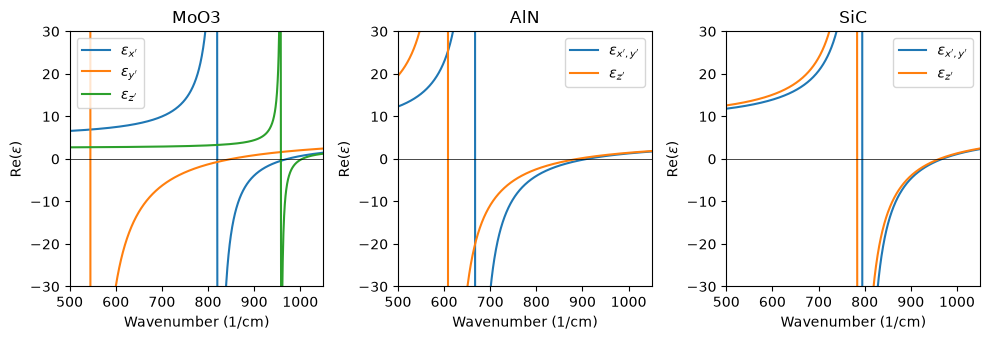

In [3]:
plt.figure(figsize=[10, 3.5])
for i, name in enumerate(eps):
    plt.subplot(1, 3, i + 1)
    for j, axis in enumerate(["x'", "y'", "z'"]):
        if name != "MoO3" and axis == "y'":
            continue
        label = (
            rf"$\varepsilon_{{{axis}}}$"
            if name == "MoO3" or axis == "z'"
            else r"$\varepsilon_{x', y'}$"
        )
        plt.plot(table, eps[name][:, j, j].real, label=label)
    plt.axhline(0, color="k", lw=0.5)
    plt.xlim(500, 1050)
    plt.ylim(-30, 30)
    plt.xlabel("Wavenumber (1/cm)")
    plt.ylabel(r"Re($\varepsilon$)")
    plt.title(name)
    plt.legend()
plt.tight_layout()
plt.show()

The Reststrahlen bands between the transversal and longitudinal phonon frequencies with a negative permittivity are different for all axes of MoO$_3$, as in Fig. 2(b) of {cite:t}`passler2020`.

## Structure

Refer to the [structure example](#example_structure) for more details.

The KRS-5 prism is the superstrate with its almost constant refractive index of 2.37 in this range, followed by an air gap of 8 µm, 1.2 µm of MoO$_3$, 1 µm of AlN, and the SiC substrate.

In [4]:
density = 1000 * u.kg / u.m**3  # irrelevant for the reflectivity

dielectrics = {
    "KRS5": ud.Dielectric(eps0=ud.Dispersion.from_ref_index(2.37)),
    "air": ud.Dielectric(eps0=ud.Dispersion.from_ref_index(1)),
}
for name in eps:
    dielectrics[name] = ud.Dielectric(
        eps0=ud.Dispersion.from_array(table, eps[name], kind="eps"), strain_model="none"
    )

thicknesses = {"KRS5": 0, "air": 8, "MoO3": 1.2, "AlN": 1, "SiC": 0}  # (µm)

layers = {}
for name, dielectric in dielectrics.items():
    layers[name] = ud.Layer(
        name,
        name,
        structural=ud.StructuralParameters(thickness=thicknesses[name] * u.um, density=density),
        optical=ud.OpticalParameters(dielectric=dielectric),
    )

S = ud.Structure("MoO3/AlN/SiC")
S.add_superstrate(layers["KRS5"])
S.add_sub_structure(layers["air"], 1)
S.add_sub_structure(layers["MoO3"], 1)
S.add_sub_structure(layers["AlN"], 1)
S.add_substrate(layers["SiC"])
S

times,sub-structure,thickness
1,air,8000 nm
1,MoO3,1200 nm
1,AlN,1000 nm


## Crystal Axes

The principal values of the dielectric tensors above are given along the axes $x'$, $y'$, and $z'$ of the crystals, which are rotated into the frame of the sample by the proper $z$-$x$-$z$ Euler angles $(\theta, \phi, \psi)$, i.e. the `euler_angles` of their {py:class}`Dielectric <udkm1Dsim.structures.dielectric.Dielectric>`, see {py:func}`euler_matrix <udkm1Dsim.structures.dielectric.euler_matrix>`.
In the frame of the sample, $z$ is the surface normal pointing towards the superstrate, $yz$ is the plane of incidence, and $x$ is along the $\sigma$ polarization, see the [scattering overview](#example_scattering_overview).
Without rotation, the crystal axes coincide with $x$, $y$, and $z$.
Then, $\phi$ turns the line of nodes $N$ from $x$ about $z$, $\theta$ tilts $z'$ from the surface normal about $N$, and $\psi$ turns $x'$ from $N$ about $z'$.

The widget below draws the frame of the sample (blue), the frame of the crystal (red), and the line of nodes (green) by the rotation matrices of {py:func}`euler_matrix <udkm1Dsim.structures.dielectric.euler_matrix>`, where the arcs follow the three successive rotations.

:::{attention}
The sliders only work in a running Jupyter notebook with the package `ipywidgets`, which is not a dependency of the **udkm1Dsim** toolbox

    pip install ipywidgets
:::

In [5]:
from ipywidgets import FloatSlider, interact
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

euler_matrix = ud.structures.dielectric.euler_matrix


def draw_euler_angles(theta=40, phi=50, psi=45):
    theta, phi, psi = np.radians([theta, phi, psi])
    R = euler_matrix(theta, phi, psi)  # columns: crystal axes x', y', z'
    N = euler_matrix(0, phi, 0) @ [1, 0, 0]  # line of nodes

    # arcs of the three successive rotations R_z(phi), R_x(theta), and R_z(psi)
    steps = np.linspace(0, 1, 50)
    arcs = {
        r"$\phi$": [0.5 * euler_matrix(0, s * phi, 0) @ [1, 0, 0] for s in steps],
        r"$\theta$": [0.8 * euler_matrix(s * theta, phi, 0) @ [0, 0, 1] for s in steps],
        r"$\psi$": [0.65 * euler_matrix(theta, phi, s * psi) @ [1, 0, 0] for s in steps],
    }

    # unit circles in the xy plane and in the rotated x'y' plane
    angles = np.linspace(0, 2 * np.pi, 100)
    circle = np.stack([np.cos(angles), np.sin(angles), np.zeros_like(angles)], axis=1)

    fig = plt.figure(figsize=[5, 5])
    ax = fig.add_subplot(projection="3d", computed_zorder=False)
    for rotation, color, prime in [(np.eye(3), "C0", ""), (R, "C3", "'")]:
        disc = circle @ rotation.T
        ax.add_collection3d(Poly3DCollection([disc], color=color, alpha=0.12, zorder=0))
        ax.plot(*disc.T, color=color, lw=0.8, zorder=1)
        for axis, name in zip(rotation.T, "xyz"):
            ax.quiver(0, 0, 0, *1.4 * axis, color=color, arrow_length_ratio=0.1, lw=2, zorder=3)
            ax.text(
                *1.55 * axis,
                f"${name}{prime}$",
                color=color,
                ha="center",
                va="center",
                fontsize=14,
                zorder=4,
            )
    ax.plot(*np.transpose([-1.15 * N, 1.15 * N]), color="C2", lw=1.5, zorder=2)
    ax.text(*1.3 * N, "$N$", color="C2", ha="center", va="center", fontsize=14, zorder=4)
    for label, arc in arcs.items():
        arc = np.array(arc)
        ax.plot(*arc.T, color="C2", lw=2, zorder=5)
        ax.text(
            *1.3 * arc[len(arc) // 2],
            label,
            color="C2",
            ha="center",
            va="center",
            fontsize=14,
            zorder=5,
        )
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_zlim(-0.7, 1.3)
    ax.set_box_aspect([1, 1, 1], zoom=1.1)
    ax.view_init(elev=20, azim=35)
    ax.set_axis_off()
    plt.show()


interact(
    draw_euler_angles,
    theta=FloatSlider(40, min=0, max=180, step=1, description="θ (deg)"),
    phi=FloatSlider(50, min=-180, max=180, step=1, description="φ (deg)"),
    psi=FloatSlider(45, min=-180, max=180, step=1, description="ψ (deg)"),
)

interactive(children=(FloatSlider(value=40.0, description='θ (deg)', max=180.0, step=1.0), FloatSlider(value=5…

<function __main__.draw_euler_angles(theta=40, phi=50, psi=45)>

The $c$-cut AlN and SiC have their optic axis $z'$ along the surface normal, i.e. they are isotropic in the plane of the surface.
Hence, only the azimuth $\Phi$ of MoO$_3$ matters, which is the angle of its $x'$ axis from the plane of incidence as in {cite:t}`passler2020`.
As $x$ is perpendicular to the plane of incidence, its Euler angles are $(0, \Phi + 90°, 0)$.

## Angle Dependence

The grazing angle $\vartheta$ of the multilayer formalisms is the angle in the superstrate, i.e. here in the prism, so that an angle of incidence $\theta_i$ from the surface normal corresponds to $\vartheta = 90° - \theta_i$, see the [scattering overview](#example_scattering_overview).
First, the reflectivity of $\sigma$- and $\pi$-polarized light, i.e. $s$ and $p$, without analyzer is calculated as a function of the angle of incidence for the azimuth $\Phi = 0°$ at 895 1/cm, which is close to the hyperbolic phonon polariton of MoO$_3$, as shown below.
As the SiC substrate is absorbing, $1 - R$ is the fraction of the light, which is absorbed in the heterostructure.

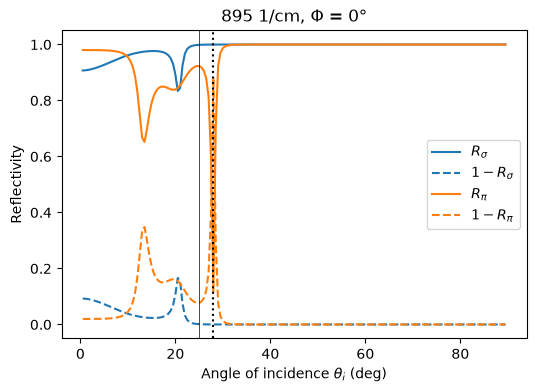

In [6]:
sim = ud.BerremanStepanov(S, True, save_data=False, disp_messages=False, progress_bar=False)
sim.wl = np.r_[1 / 895] * u.cm
incidences = np.r_[0.5:89.6:0.5]  # deg
sim.theta = (90 - incidences) * u.deg
layers["MoO3"].optical.dielectric.euler_angles = (0, 90, 0) * u.deg

plt.figure(figsize=[6, 4])
for pol in ["sigma", "pi"]:
    sim.set_polarization(pol, "none")
    R = sim.homogeneous_reflectivity_transmissivity()[0][0]
    line = plt.plot(incidences, R, label=rf"$R_\{pol}$")
    plt.plot(incidences, 1 - R, "--", color=line[0].get_color(), label=rf"$1 - R_\{pol}$")
plt.axvline(np.rad2deg(np.arcsin(1 / 2.37)), color="k", lw=0.5)
plt.axvline(28, color="k", ls=":")
plt.xlabel(r"Angle of incidence $\theta_i$ (deg)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title(r"895 1/cm, $\Phi$ = 0°")
plt.show()

Below the critical angle of total reflection between KRS-5 and air of about 25° (solid line), the light propagates through the air gap and is mostly reflected by the Reststrahlen bands of the crystals, apart from resonances of the layers, where it is partly absorbed.
Beyond it, the evanescent wave tunnels through the air gap and excites the polariton for the $\pi$ polarization only, which results in the dip of $R_\pi$ at the angle of incidence of 28° of {cite:t}`passler2020` (dotted line).

## Azimuthal Dependence

The reflectance $R_p$ of {cite:t}`passler2020` is the one of $p$-polarized light into $p$-polarized light, i.e. $|r_{\pi\pi}|^2$ of the Jones matrix of the reflection in the $(\sigma, \pi)$ basis.
In addition, the cross-polarized reflectance $|r_{\sigma\pi}|^2$ of $p$- into $s$-polarized light is calculated, which results from the in-plane anisotropy of MoO$_3$.
The Jones matrices are calculated once for every azimuth, from which {py:meth}`calc_reflectivity_transmissivity() <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.calc_reflectivity_transmissivity>` gives the reflectances for the incoming $\pi$ polarization and the analyzer along $\pi$ or $\sigma$.

In [7]:
sim.wl = 1 / wavenumbers
sim.theta = np.r_[62] * u.deg

azimuths = np.r_[0:181:2]  # deg
R_pp = np.zeros([len(azimuths), len(wavenumbers)])
R_sp = np.zeros_like(R_pp)
for i, azimuth in enumerate(azimuths):
    layers["MoO3"].optical.dielectric.euler_angles = (0, 90 + azimuth, 0) * u.deg
    Ref, _, Trans, _ = sim.homogeneous_jones_matrices()
    sim.set_polarization("pi", "pi")
    R_pp[i] = sim.calc_reflectivity_transmissivity(Ref, Trans)[0][:, 0]
    sim.set_polarization("pi", "sigma")
    R_sp[i] = sim.calc_reflectivity_transmissivity(Ref, Trans)[0][:, 0]

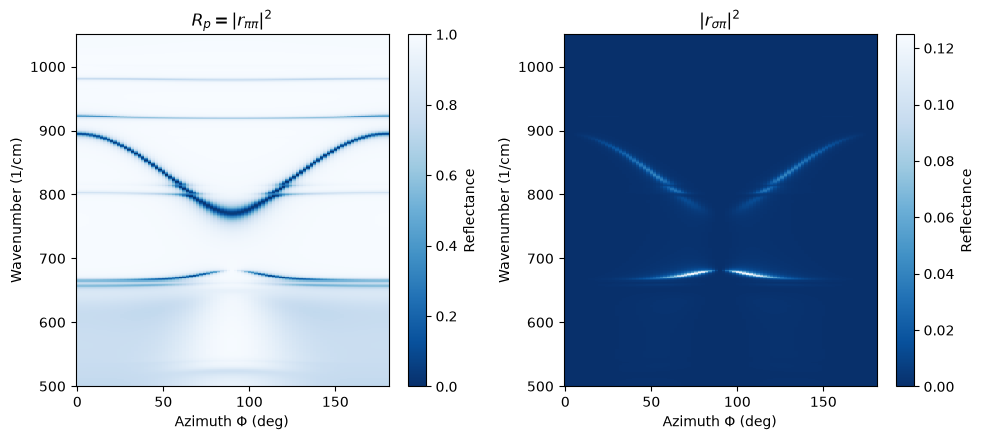

In [8]:
plt.figure(figsize=[10, 4.5])
for i, (R, title) in enumerate(
    [(R_pp, r"$R_p = |r_{\pi\pi}|^2$"), (R_sp, r"$|r_{\sigma\pi}|^2$")]
):
    plt.subplot(1, 2, i + 1)
    plt.pcolormesh(
        azimuths,
        wavenumbers.magnitude,
        R.T,
        shading="auto",
        cmap="Blues_r",
        vmin=0,
        vmax=1 if i == 0 else None,
    )
    plt.colorbar(label="Reflectance")
    plt.xlabel(r"Azimuth $\Phi$ (deg)")
    plt.ylabel("Wavenumber (1/cm)")
    plt.title(title)
plt.tight_layout()
plt.show()

The reflectance $R_p$ resembles Fig. 2(c) of {cite:t}`passler2020`.
It shows several sharp dips at about 660 1/cm, 800 1/cm, 920 1/cm, and 980 1/cm, which are mostly independent of the azimuth, as they belong to the surface phonon polaritons of the uniaxial AlN and SiC and the out-of-plane axis of MoO$_3$.
The prominent dip between about 770 1/cm and 900 1/cm strongly disperses with the azimuth.
It is the hyperbolic phonon polariton of MoO$_3$ in its in-plane Reststrahlen bands, whose effective permittivity depends on the azimuth.
{cite:t}`passler2020` show by the layer-resolved absorption that this polariton is mostly absorbed in MoO$_3$ above the transversal phonon frequency of SiC and leaks into the SiC substrate below it.
The cross-polarized reflectance vanishes for $\Phi = 0°$ and $90°$, where the principal axes of MoO$_3$ are in and perpendicular to the plane of incidence, and follows the dispersive polariton and the mode at about 680 1/cm.

The in-plane anisotropy is best seen in a polar plot of $R_p$, where the reflectance for $\Phi$ and $\Phi + 180°$ is identical.

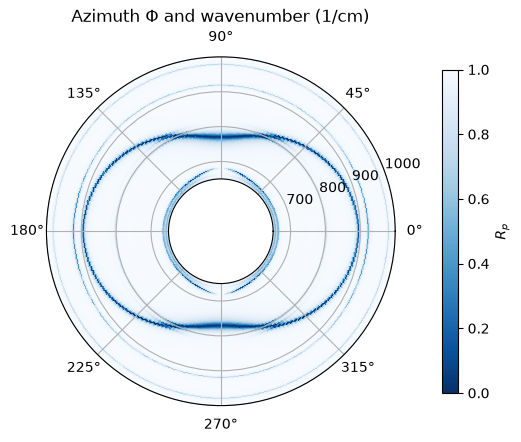

In [9]:
phi = np.deg2rad(np.r_[azimuths, azimuths[1:] + 180])
R_polar = np.r_[R_pp, R_pp[1:]]

plt.figure(figsize=[6, 6])
ax = plt.subplot(projection="polar")
mesh = ax.pcolormesh(
    phi, wavenumbers.magnitude, R_polar.T, shading="auto", vmin=0, vmax=1, cmap="Blues_r"
)
ax.set_rorigin(500)
ax.set_rlim(650, 1000)
ax.set_rticks([700, 800, 900, 1000])
ax.set_rlabel_position(20)
plt.colorbar(mesh, ax=ax, shrink=0.7, pad=0.1, label=r"$R_p$")
ax.set_title(r"Azimuth $\Phi$ and wavenumber (1/cm)")
plt.show()

The electric field profiles and the layer-resolved absorption are planned for a future version of the **udkm1Dsim** toolbox.